In [186]:
cd /content/drive/MyDrive/Colab Notebooks/Assignment2

/content/drive/MyDrive/Colab Notebooks/Assignment2


In [207]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from gymnasium.wrappers import RecordVideo
import os
from IPython import display as ipythondisplay
from IPython.display import HTML
import base64
import time

PERPENDICULAR_ACTIONS = { #define perpendicular actions for slipping perpendicularly
    0: (3, 1), #up
    1: (0, 2), #right
    2: (1, 3), #down
    3: (2, 0)  #left
}
intended_prob = 0.75 #probability of intended action
perpendicular_prob = (1.0 - intended_prob) / 2.0


alpha= 0.1
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.95
epsilon_min = 0.01

# self, n_states=48, n_actions=4, learning_rate=0.1,
#                  discount_factor=0.99, epsilon=1.0, epsilon_decay=0.995,
#                  epsilon_min=0.01
class QLearningAgent:
    def __init__(self, n_states=48, n_actions=4, learning_rate=alpha,
                 discount_factor=gamma, epsilon=epsilon, epsilon_decay=epsilon_decay,
                 epsilon_min=epsilon_min):
        """
        Q-Learning Agent for CliffWalking

        Args:
            n_states: Number of discrete states in CliffWalking (48)
            n_actions: Number of possible actions (4)
            learning_rate: Learning rate (alpha)
            discount_factor: Discount factor (gamma)
            epsilon: Initial exploration rate
            epsilon_decay: Rate of epsilon decay
            epsilon_min: Minimum epsilon value
        """
        self.n_states = n_states
        self.n_actions = n_actions
        self.lr = learning_rate
        self.gamma = discount_factor
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        # Initialize Q-table for discrete states and actions
        self.q_table = np.zeros((n_states, n_actions))

    def get_action(self, state, training=True):
        """Epsilon-greedy action selection"""
        if training and np.random.random() < self.epsilon:
            return np.random.randint(self.n_actions)
        else:
            return np.argmax(self.q_table[state])

    def update(self, state, action, reward, next_state, done):
        """Update Q-table using Q-learning formula"""
        current_q = self.q_table[state][action]

        if done:
            target_q = reward
        else:
            max_next_q = np.max(self.q_table[next_state])
            target_q = reward + self.gamma * max_next_q

        # Update Q-value
        self.q_table[state][action] += self.lr * (target_q - current_q)

    def decay_epsilon(self):
        """Decay exploration rate"""
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


def train_agent(n_episodes=500, render=False):
    """Train the Q-learning agent on CliffWalking"""
    env = gym.make("CliffWalking-v1")
    agent = QLearningAgent(n_states=env.observation_space.n, n_actions=env.action_space.n)
    unwrapped_env = env.unwrapped

    for state in range(unwrapped_env.observation_space.n):
        for action in range(unwrapped_env.action_space.n):
            # Extract the original transition from the single-element lists with format (probability, next_state, reward, terminated)
            orig_t = unwrapped_env.P[state][action][0]

            if orig_t:
                p_left, p_right = PERPENDICULAR_ACTIONS[action]

                left_t = unwrapped_env.P[state][p_left][0]
                right_t = unwrapped_env.P[state][p_right][0]

                # Rebuild transitions (probability, next_state, reward, terminated)
                unwrapped_env.P[state][action] = [
                    (intended_prob, orig_t[1], orig_t[2], orig_t[3]),
                    (perpendicular_prob, left_t[1], left_t[2], left_t[3]),
                    (perpendicular_prob, right_t[1], right_t[2], right_t[3])
                ]
    env = unwrapped_env

    episode_rewards = []

    for episode in range(n_episodes):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            # Select and perform action
            action = agent.get_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Update Q-table
            agent.update(state, action, reward, next_state, done)

            state = next_state
            total_reward += reward

        # Decay epsilon after each episode
        agent.decay_epsilon()
        episode_rewards.append(total_reward)

        # Print progress
        if (episode + 1) % 100 == 0:
            avg_reward = np.mean(episode_rewards[-100:])
            print(f"Episode {episode + 1}/{n_episodes}, "
                  f"Avg Reward (last 100): {avg_reward:.2f}, "
                  f"Epsilon: {agent.epsilon:.3f}")

    env.close()
    return agent, episode_rewards

def plot_results(episode_rewards):
    """Plot training results"""
    fig = plt.figure(figsize=(10, 5))
    plt.plot(episode_rewards, alpha=0.3, label='Episode Reward')

    # Moving average
    window = 50
    if len(episode_rewards) >= window:
        moving_avg = np.convolve(episode_rewards,
                                np.ones(window)/window,
                                mode='valid')
        plt.plot(range(window-1, len(episode_rewards)),
                 moving_avg,
                 label=f'{window}-Episode Moving Average')

    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title('Q-Learning Training Progress on CliffWalking')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show() # draw the plot

def show_video(video_folder):
    """Helper to embed and show mp4 videos inside Colab"""
    mp4list = [f for f in os.listdir(video_folder) if f.endswith('.mp4')]
    if len(mp4list) > 0:
        mp4 = os.path.join(video_folder, sorted(mp4list)[-1])
        video = open(mp4, 'r+b').read()
        encoded = base64.b64encode(video)
        ipythondisplay.display(HTML(data='''<video alt="test" autoplay
                    loop controls style="height: 300px;">
                    <source src="data:video/mp4;base64,{0}" type="video/mp4" />
                 </video>'''.format(encoded.decode('ascii'))))
    else:
        print("No mp4 video found.")

def test_agent(agent, n_episodes=10, record_video=False, video_folder='./videos'):
    """Test the trained agent and visualize/save"""
    if record_video:
        os.makedirs(video_folder, exist_ok=True)
        base_env = gym.make('CliffWalking-v1', render_mode='rgb_array')
        # Build transitions in the unwrapped environment first
        unwrapped_env = base_env.unwrapped
        for state in range(unwrapped_env.observation_space.n):
            for action in range(unwrapped_env.action_space.n):
                orig_t = unwrapped_env.P[state][action][0]
                if orig_t:
                    p_left, p_right = PERPENDICULAR_ACTIONS[action]
                    left_t = unwrapped_env.P[state][p_left][0]
                    right_t = unwrapped_env.P[state][p_right][0]
                    unwrapped_env.P[state][action] = [
                        (intended_prob, orig_t[1], orig_t[2], orig_t[3]),
                        (perpendicular_prob, left_t[1], left_t[2], left_t[3]),
                        (perpendicular_prob, right_t[1], right_t[2], right_t[3])
                    ]
        env=unwrapped_env
        env = RecordVideo(env, video_folder=video_folder,
                          episode_trigger=lambda x: True,
                          name_prefix='cliffwalking-qlearning',
                          disable_logger=True)
    else:
        env = gym.make('CliffWalking-v1', render_mode='rgb_array')
        unwrapped_env = env.unwrapped
        for state in range(unwrapped_env.observation_space.n):
            for action in range(unwrapped_env.action_space.n):
                orig_t = unwrapped_env.P[state][action][0]
                if orig_t:
                    p_left, p_right = PERPENDICULAR_ACTIONS[action]
                    left_t = unwrapped_env.P[state][p_left][0]
                    right_t = unwrapped_env.P[state][p_right][0]
                    unwrapped_env.P[state][action] = [
                        (intended_prob, orig_t[1], orig_t[2], orig_t[3]),
                        (perpendicular_prob, left_t[1], left_t[2], left_t[3]),
                        (perpendicular_prob, right_t[1], right_t[2], right_t[3])
                    ]
        env = unwrapped_env

    total_reward = np.zeros(n_episodes)
    for episode in range(n_episodes):
        state, _ = env.reset()
        total_reward[episode] = 0
        done = False

        # Real-time frame display only if not recording video
        if not record_video:
            fig, ax = plt.subplots(figsize=(6, 3))
            img = ax.imshow(env.render())
            plt.axis('off')

        while not done:
            action = agent.get_action(state, training=False)
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_reward[episode] += reward

            if not record_video:
                img.set_data(env.render())
                ipythondisplay.clear_output(wait=True)
                ipythondisplay.display(plt.gcf())
                pause_time = 0.05
                time.sleep(pause_time)

        if not record_video:
            plt.close(fig)
        # print(f"Test Episode {episode + 1}: Reward = {total_reward[episode]}")
    # Print average results
    avg_reward = np.mean(total_reward)
    print(f"Avg Reward: {avg_reward:.2f}, ")

    print("\n--- Test Summary ---")
    for episode in range(n_episodes):
        print(f"Test Episode {episode + 1}: Reward = {total_reward[episode]}")
    # Print average results
    avg_reward = np.mean(total_reward)
    print(f"Avg Reward (last 5): {avg_reward:.2f}, ")

    env.close()

    if record_video:
        print(f"\nVideos saved to: {video_folder}")
        show_video(video_folder)

Training Q-Learning agent on CliffWalking...
alpha=0.1 gamma=0.99 epsilon=1.0 epsilon_decay=0.95 epsilon_min=0.01 noise=0.0

Episode 100/500, Avg Reward (last 100): -1615.11, Epsilon: 0.010
Episode 200/500, Avg Reward (last 100): -28.76, Epsilon: 0.010
Episode 300/500, Avg Reward (last 100): -19.66, Epsilon: 0.010
Episode 400/500, Avg Reward (last 100): -16.57, Epsilon: 0.010
Episode 500/500, Avg Reward (last 100): -20.52, Epsilon: 0.010


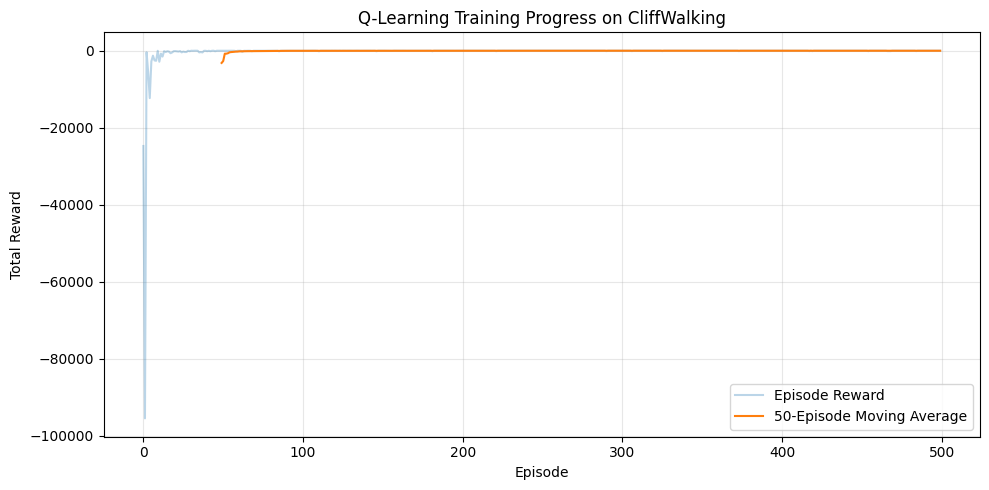

In [204]:

# Train the agent
print("Training Q-Learning agent on CliffWalking...")
print(f"alpha={alpha} gamma={gamma} epsilon={epsilon} epsilon_decay={epsilon_decay} epsilon_min={epsilon_min} noise={1-intended_prob}\n")
agent, rewards = train_agent(n_episodes=500)
plot_results(rewards)



In [208]:
# test_agent(agent, n_episodes=5, record_video=False)
print(f"alpha={alpha} gamma={gamma} epsilon={epsilon} epsilon_decay={epsilon_decay} epsilon_min={epsilon_min} noise={1-intended_prob}\n")
test_agent(agent, n_episodes=5, record_video=True,video_folder='./stoch_videos')

alpha=0.1 gamma=0.99 epsilon=1.0 epsilon_decay=0.95 epsilon_min=0.01 noise=0.25

Avg Reward: -104.40, 

--- Test Summary ---
Test Episode 1: Reward = -223.0
Test Episode 2: Reward = -15.0
Test Episode 3: Reward = -252.0
Test Episode 4: Reward = -15.0
Test Episode 5: Reward = -17.0
Avg Reward (last 5): -104.40, 

Videos saved to: ./stoch_videos
